# CALPHAD Co–Fe Binary Phase Diagrams



This notebook generates the three requested Co–Fe views using `CoFe-17Wan.tdb`. “Atomic mass” is interpreted here as **atomic percent (at.%)**, so composition is calculated and plotted with the atomic/mole fraction variable `X`; this differs from the previous mass-percent (`W`) notebook.



The calculation cells produce a left-to-right pair of diagrams for both composition directions:



-- **Co–Fe:** Fe is the dissolving element.

-- **Fe–Co:** Co is the dissolving element.



The settings cell is designed for future TDB selection from the `database` folder and validates that the selected binary elements and requested phases exist in the chosen database.

In [1]:
from collections.abc import Callable, Iterable
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from pycalphad import Database, equilibrium
from pycalphad.mapping import BinaryStrategy, plot_binary
import pycalphad.variables as v


PHASE_AMOUNT_TOLERANCE = 1e-6
TEMPERATURE_TOLERANCE = 0.1
VACANCY_COMPONENT = "VA"

## Database and calculation settings

`database_files` lists the available `.tdb` databases automatically. Keep `selected_database` set to `CoFe-17Wan.tdb` for this work; later, choose another entry and update `binary_elements` to two elements supported by that database.

The diagrams use atomic percent (at.%):

- Full-system diagrams use $0$–$100\,\mathrm{at.\%}$.
- Focused diagrams use $10$–$25\,\mathrm{at.\%}$.
- `all_phases` contains the phase candidates required for the equilibrium focused liquidus/solidus calculation. `FCC_A1`, `BCC_A2`, and `B2_BCC` can each occur next to liquid in this composition range; therefore no single fixed solid phase is valid.
- `equilibrium_temperature_range` is the interval used to calculate the high-temperature equilibrium phase map.
- `focused_y_axis_ranges` independently controls the step 3 y-axis limits for each dissolving element. Set a value to `(minimum, maximum)`, or to `None` to display the full calculation range for that diagram.
- `focused_boundary_temperature_ranges` provides tighter, direction-specific search ranges for the direct **all-phase equilibrium** boundary calculations in step 3.
- `focused_boundary_curve_step_atomic_percent` controls the resolution of the directly evaluated step 3 boundary curves; a smaller value creates a smoother curve but increases calculation time.
- `focused_data_point_atomic_percents` selects the compositions sampled along the equilibrium solidus and liquidus boundaries in step 3.

In [2]:
DATABASE_DIRECTORY = Path("database")

database_files = sorted(DATABASE_DIRECTORY.glob("*.tdb"))

# Keep CoFe-17Wan.tdb for the current work. Change both settings together
# when calculating a different binary system in the future.
selected_database = DATABASE_DIRECTORY / "CoFe-17Wan.tdb"
binary_elements = ("CO", "FE")

# Temperature domains and resolution: start, end, step in K.
temperature_range = (300.0, 1850.0, 10.0)

# The stable solid next to liquid varies over the focused region, so retain all
# relevant phase candidates for the high-temperature equilibrium calculation.
equilibrium_temperature_range = (1600.0, 1850.0, 10.0)

# Focused direct-boundary searches: one range for each dissolving element.
# These brackets cover the verified all-phase liquidus/solidus transitions.
focused_boundary_temperature_ranges = {
    "FE": (1740.0, 1770.0, 5.0),  # Co–Fe: Fe dissolving
    "CO": (1760.0, 1800.0, 5.0),  # Fe–Co: Co dissolving
}

# Step 3 display ranges only; use None for the full calculation range.
focused_y_axis_ranges = {
    "FE": (1740.0, 1765.0),  # Co–Fe: Fe dissolving
    "CO": (1760.0, 1800.0),  # Fe–Co: Co dissolving
}

# Directly evaluate boundary curves at this atomic-percent interval.
focused_boundary_curve_step_atomic_percent = 0.5

# Composition points for the step 3 equilibrium boundary tables.
# Include the 25.0 at.% endpoint in both composition directions.
focused_data_point_atomic_percents = {
    "FE": (*range(10, 26, 2), 25.0),
    "CO": (*range(10, 26, 2), 25.0),
}

pressure = 101325.0  # Pa

# Thermodynamically relevant phase candidates in CoFe-17Wan.tdb.
# Note: pycalphad warns that B2_BCC magnetic partitioning is approximate.
all_phases = ("LIQUID", "BCC_A2", "B2_BCC", "FCC_A1", "HCP_A3")

# Required dissolving-element directions: Co–Fe, then Fe–Co.
dissolving_elements = ("FE", "CO")

# Requested composition windows, expressed as atomic fraction.
full_atomic_fraction_range = (0.0, 1.0, 0.02)
focused_atomic_fraction_range = (0.10, 0.25, 0.005)

## Thermodynamic calculation and plotting helpers



The helpers below:



1. validate the selected database, binary elements, and phases;

2. calculate stable phase amounts at a fixed **atomic fraction**;

3. refine the first solidus/liquidus transition while heating to $0.1\,\mathrm{K}$; and

4. generate a pair of diagrams, with one direction per dissolving element.

In [3]:
def validated_components(database: Database, elements: tuple[str, str]) -> list[str]:
    """Return binary components including the vacancy component required by the TDB."""
    database_elements = {element.upper() for element in database.elements}
    requested_elements = {element.upper() for element in elements}
    missing_elements = requested_elements - database_elements
    if missing_elements:
        raise ValueError(
            f"Database is missing requested elements: {', '.join(sorted(missing_elements))}."
        )
    components = [element.upper() for element in elements]
    if VACANCY_COMPONENT in database_elements:
        components.append(VACANCY_COMPONENT)
    return components


def validate_calculation_setup(
    database: Database, elements: tuple[str, str], phases: tuple[str, ...],
) -> list[str]:
    """Validate requested elements and phases, returning calculation components."""
    if len(elements) != 2:
        raise ValueError("Exactly two binary elements are required.")
    components = validated_components(database, elements)
    database_phases = {phase.upper() for phase in database.phases}
    missing_phases = {phase.upper() for phase in phases} - database_phases
    if missing_phases:
        raise ValueError(
            f"Database is missing requested phases: {', '.join(sorted(missing_phases))}."
        )
    return components


def phase_amounts_at_composition(
    database: Database,
    components: list[str],
    phases: tuple[str, ...],
    dissolving_element: str,
    atomic_fraction: float,
    temperature: float,
) -> dict[str, float]:
    """Return equilibrium phase amounts for one temperature and composition."""
    result = equilibrium(
        database, components, phases,
        {
            v.X(dissolving_element): atomic_fraction,
            v.T: temperature, v.P: pressure, v.N: 1,
        },
    )
    return {
        phase_name.upper(): float(phase_amount)
        for phase_name, phase_amount in zip(result.Phase.values.ravel(), result.NP.values.ravel())
        if phase_name and phase_name != ""
    }


def find_transition_temperature(
    predicate: Callable[[dict[str, float]], bool],
    database: Database,
    components: list[str],
    phases: tuple[str, ...],
    dissolving_element: str,
    atomic_fraction: float,
    search_temperature_range: tuple[float, float, float],
) -> float | None:
    """Locate the first heating temperature at which a phase predicate is true."""
    temperature_minimum, temperature_maximum, temperature_step = search_temperature_range
    temperatures = np.arange(
        temperature_minimum, temperature_maximum + temperature_step, temperature_step
    )
    previous_temperature = float(temperatures[0])
    previous_result = predicate(
        phase_amounts_at_composition(
            database, components, phases, dissolving_element, atomic_fraction, previous_temperature
        )
    )
    if previous_result:
        return previous_temperature

    for temperature in temperatures[1:]:
        temperature = float(temperature)
        current_result = predicate(
            phase_amounts_at_composition(
                database, components, phases, dissolving_element, atomic_fraction, temperature
            )
        )
        if current_result:
            lower_temperature, upper_temperature = previous_temperature, temperature
            while upper_temperature - lower_temperature > TEMPERATURE_TOLERANCE:
                middle_temperature = (lower_temperature + upper_temperature) / 2
                middle_result = predicate(
                    phase_amounts_at_composition(
                        database, components, phases, dissolving_element, atomic_fraction, middle_temperature
                    )
                )
                if middle_result:
                    upper_temperature = middle_temperature
                else:
                    lower_temperature = middle_temperature
            return upper_temperature
        previous_temperature, previous_result = temperature, current_result
    return None


def equilibrium_solidus_and_liquidus(
    database: Database,
    components: list[str],
    dissolving_element: str,
    atomic_fraction: float,
    search_temperature_range: tuple[float, float, float],
) -> tuple[float | None, float | None, str]:
    """Calculate all-phase equilibrium solidus, liquidus, and adjacent solid phases."""
    solidus = find_transition_temperature(
        lambda phase_amounts: phase_amounts.get("LIQUID", 0.0) > PHASE_AMOUNT_TOLERANCE,
        database, components, all_phases, dissolving_element, atomic_fraction,
        search_temperature_range,
    )
    liquidus = find_transition_temperature(
        lambda phase_amounts: phase_amounts.get("LIQUID", 0.0) >= 1 - PHASE_AMOUNT_TOLERANCE,
        database, components, all_phases, dissolving_element, atomic_fraction,
        search_temperature_range,
    )
    if solidus is None:
        return solidus, liquidus, "not found"

    below_solidus = phase_amounts_at_composition(
        database, components, all_phases, dissolving_element, atomic_fraction,
        solidus - TEMPERATURE_TOLERANCE,
    )
    solid_phases = sorted(
        phase_name
        for phase_name, phase_amount in below_solidus.items()
        if phase_name != "LIQUID" and phase_amount > PHASE_AMOUNT_TOLERANCE
    )
    return solidus, liquidus, " + ".join(solid_phases) or "not found"


def system_label(elements: tuple[str, str], dissolving_element: str) -> str:
    """Return the system label ordered as solvent–dissolving element."""
    solvent = next(element for element in elements if element != dissolving_element)
    return f"{solvent}–{dissolving_element} ({dissolving_element} dissolving)"


def merge_composition_set_legend(axis: Axes) -> None:
    """Show composition sets such as BCC_A2#2 only under the base phase name."""
    phase_legend = axis.get_legend()
    if phase_legend is None:
        return
    handles: list[Patch] = []
    labels: list[str] = []
    for handle, text in zip(phase_legend.legend_handles, phase_legend.get_texts()):
        base_phase = text.get_text().split("#", maxsplit=1)[0]
        if base_phase not in labels:
            handles.append(handle)
            labels.append(base_phase)
    axis.legend(handles=handles, labels=labels, loc="center left", bbox_to_anchor=(1, 0.5))


def plot_diagram_pair(
    database: Database,
    components: list[str],
    phases: tuple[str, ...],
    composition_range: tuple[float, float, float],
    diagram_temperature_range: tuple[float, float, float],
    description: str,
) -> None:
    """Plot one phase diagram for each dissolving-element direction."""
    figure, axes = plt.subplots(1, 2, figsize=(15, 7), dpi=150)
    for axis, dissolving_element in zip(axes, dissolving_elements):
        strategy = BinaryStrategy(
            database, components, phases=phases,
            conditions={
                v.X(dissolving_element): composition_range,
                v.T: diagram_temperature_range, v.P: pressure, v.N: 1,
            },
            plot_kwargs={"ax": axis},
        )
        strategy.do_map()
        plot_binary(strategy, x=v.X(dissolving_element), y=v.T, ax=axis)
        merge_composition_set_legend(axis)
        axis.set_xlim(composition_range[:2])
        axis.set_ylim(diagram_temperature_range[:2])
        axis.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        axis.set_xlabel(f"Atomic Percent {dissolving_element} (at.%)")
        axis.set_ylabel("Temperature (K)")
        axis.set_title(f"{system_label(binary_elements, dissolving_element)}\n{description}")
        axis.grid(True, which="both", linestyle="--", linewidth=0.5)
    figure.tight_layout()
    plt.show()

In [4]:
def calculate_boundary_data(
    database: Database,
    components: list[str],
    dissolving_element: str,
    atomic_percents: Iterable[float],
) -> pd.DataFrame:
    """Directly calculate all-phase equilibrium solidus and liquidus data."""
    minimum_fraction, maximum_fraction = focused_atomic_fraction_range[:2]
    compositions = np.asarray(tuple(atomic_percents), dtype=float)
    fractions = compositions / 100
    if np.any(fractions < minimum_fraction) or np.any(fractions > maximum_fraction):
        raise ValueError(
            "All focused atomic-percent values must lie within "
            "focused_atomic_fraction_range."
        )

    search_temperature_range = focused_boundary_temperature_ranges[dissolving_element]
    records: list[dict[str, float | str | None]] = []
    for atomic_percent, atomic_fraction in zip(compositions, fractions):
        solidus, liquidus, solid_phases = equilibrium_solidus_and_liquidus(
            database, components, dissolving_element, atomic_fraction, search_temperature_range
        )
        records.append(
            {
                f"{dissolving_element} (at.%)": atomic_percent,
                "Equilibrium solidus (K)": solidus,
                "Equilibrium liquidus (K)": liquidus,
                "Stable solid phase(s) below solidus": solid_phases,
            }
        )
    return pd.DataFrame(records)


def calculate_focused_boundary_data(
    database: Database, components: list[str], dissolving_element: str,
) -> pd.DataFrame:
    """Calculate table values at the user-selected step 3 compositions."""
    return calculate_boundary_data(
        database, components, dissolving_element,
        focused_data_point_atomic_percents[dissolving_element],
    )


def focused_curve_compositions() -> np.ndarray:
    """Return a composition grid, including both focused-range endpoints."""
    start, end = np.asarray(focused_atomic_fraction_range[:2]) * 100
    step = focused_boundary_curve_step_atomic_percent
    if step <= 0:
        raise ValueError("focused_boundary_curve_step_atomic_percent must be positive.")
    return np.append(np.arange(start, end, step), end)


def plot_focused_diagrams(
    database: Database,
    components: list[str],
    display_temperature_ranges: dict[str, tuple[float, float] | None],
) -> None:
    """Plot all-phase equilibrium solidus/liquidus curves, markers, and tables."""
    curve_compositions = focused_curve_compositions()
    for dissolving_element in dissolving_elements:
        display_temperature_range = display_temperature_ranges.get(dissolving_element)
        if display_temperature_range is not None:
            display_minimum, display_maximum = display_temperature_range
            if display_minimum >= display_maximum:
                raise ValueError(
                    f"Focused y-axis range for {dissolving_element} must increase."
                )

        curve_data = calculate_boundary_data(
            database, components, dissolving_element, curve_compositions
        )
        boundary_data = calculate_focused_boundary_data(
            database, components, dissolving_element
        )
        composition_column = f"{dissolving_element} (at.%)"
        solidus_column = "Equilibrium solidus (K)"
        liquidus_column = "Equilibrium liquidus (K)"
        curve_x = curve_data[composition_column].to_numpy(dtype=float) / 100
        solidus_curve = pd.to_numeric(
            curve_data[solidus_column], errors="coerce"
        ).to_numpy(dtype=float)
        liquidus_curve = pd.to_numeric(
            curve_data[liquidus_column], errors="coerce"
        ).to_numpy(dtype=float)
        valid_curve = (
            np.isfinite(curve_x)
            & np.isfinite(solidus_curve)
            & np.isfinite(liquidus_curve)
        )
        if not valid_curve.any():
            raise ValueError(
                f"No equilibrium liquidus/solidus boundaries were found for "
                f"{dissolving_element} within its focused_boundary_temperature_ranges setting."
            )

        figure, axis = plt.subplots(figsize=(8, 7), dpi=150)
        axis.plot(curve_x[valid_curve], solidus_curve[valid_curve], color="#00538A", linewidth=1.4)
        axis.plot(curve_x[valid_curve], liquidus_curve[valid_curve], color="#F4C800", linewidth=1.4)
        axis.fill_between(
            curve_x[valid_curve], solidus_curve[valid_curve], liquidus_curve[valid_curve],
            color="#F4C800", alpha=0.12, label="Equilibrium solid + LIQUID",
        )
        axis.legend(
            handles=[
                Patch(color="#00538A", label="Equilibrium solidus"),
                Patch(color="#F4C800", label="LIQUID"),
            ],
            loc="upper left", bbox_to_anchor=(1.02, 1),
        )

        point_x = boundary_data[composition_column].to_numpy(dtype=float) / 100
        solidus_points = pd.to_numeric(
            boundary_data[solidus_column], errors="coerce"
        ).to_numpy(dtype=float)
        liquidus_points = pd.to_numeric(
            boundary_data[liquidus_column], errors="coerce"
        ).to_numpy(dtype=float)
        valid_solidus_points = np.isfinite(point_x) & np.isfinite(solidus_points)
        valid_liquidus_points = np.isfinite(point_x) & np.isfinite(liquidus_points)
        axis.scatter(
            point_x[valid_solidus_points], solidus_points[valid_solidus_points],
            color="#00538A", edgecolor="white", linewidth=0.6, s=36, zorder=4,
        )
        axis.scatter(
            point_x[valid_liquidus_points], liquidus_points[valid_liquidus_points],
            color="#F4C800", edgecolor="white", linewidth=0.6, s=36, zorder=4,
        )
        axis.set_xlim(focused_atomic_fraction_range[:2])
        axis.set_ylim(
            display_temperature_range
            or focused_boundary_temperature_ranges[dissolving_element][:2]
        )
        axis.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        axis.set_xlabel(f"Atomic Percent {dissolving_element} (at.%)")
        axis.set_ylabel("Temperature (K)")
        axis.set_title(
            f"{system_label(binary_elements, dissolving_element)}\n"
            "Equilibrium liquidus/solidus region (10–25 at.%)"
        )
        axis.grid(True, which="both", linestyle="--", linewidth=0.5)
        figure.tight_layout()
        plt.show()
        print(
            f"{system_label(binary_elements, dissolving_element)}: "
            "selected equilibrium solidus and liquidus temperatures"
        )
        display(boundary_data.round(1))

## 1. Full binary system: all phases

This view spans the complete $0$–$100\,\mathrm{at.\%}$ composition range and includes all thermodynamically relevant phase candidates: `LIQUID`, `BCC_A2`, `B2_BCC`, `FCC_A1`, and `HCP_A3`. It produces:

- Co–Fe with Fe as the dissolving element; and
- Fe–Co with Co as the dissolving element.

Database: CoFe-17Wan.tdb
Components: CO, FE, VA
All phases: LIQUID, BCC_A2, B2_BCC, FCC_A1, HCP_A3


/home/volodymyr/Desktop/CALPHAD_analysis/calphad-venv/lib/python3.12/site-packages/pycalphad/model.py:1380: UserWarning: The order-disorder model for "B2_BCC" has a contribution from the physical property model `magnetic_energy`. Partitioned physical properties are not correctly substituted into the disordered part of the energy. THE GIBBS ENERGY CALCULATED FOR THIS PHASE MAY BE INCORRECT. Please see the discussion in https://github.com/pycalphad/pycalphad/pull/311 for more details.
  warnings.warn(


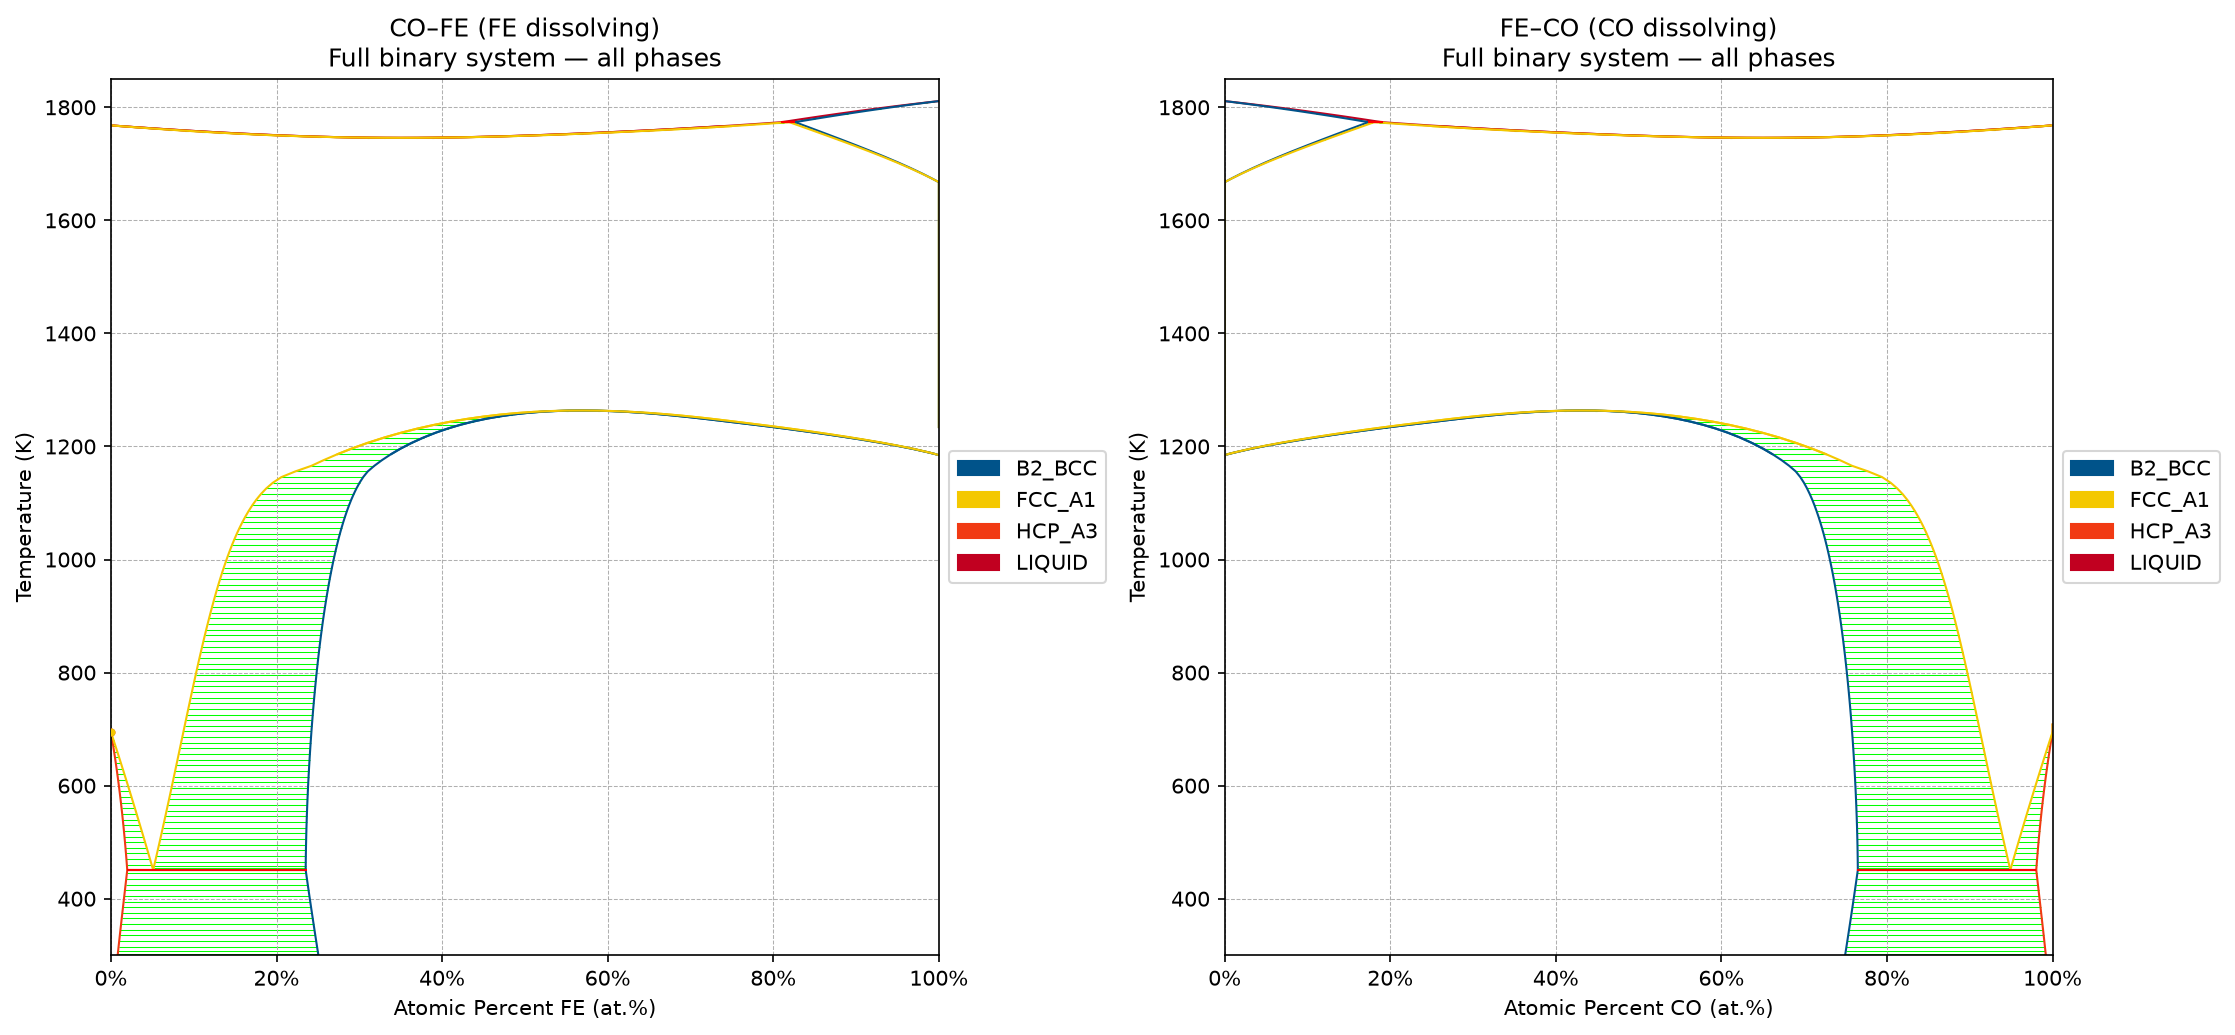

In [5]:
database = Database(selected_database)
calculation_components = validate_calculation_setup(
    database,
    binary_elements,
    all_phases,
)

print(f"Database: {selected_database.name}")
print(f"Components: {', '.join(calculation_components)}")
print(f"All phases: {', '.join(all_phases)}")

plot_diagram_pair(
    database,
    calculation_components,
    all_phases,
    full_atomic_fraction_range,
    temperature_range,
    "Full binary system — all phases",
)

## 2. Full binary system: high-temperature equilibrium

This $0$–$100\,\mathrm{at.\%}$ view uses all phase candidates in `all_phases` through the melting interval.

> **No fixed solid phase pair:** within the focused 10–25 at.% ranges, the stable solid adjacent to liquid changes among `FCC_A1`, `BCC_A2`, and `B2_BCC`. A constrained `BCC_A2` + `LIQUID` calculation is therefore metastable at part of the range and cannot provide the equilibrium solidus.

> **Database limitation:** `B2_BCC` is retained because the database predicts it near melting, but pycalphad reports an order–disorder magnetic-energy warning for this phase. Treat boundaries involving `B2_BCC` as database-model results and validate them against independent data when necessary.

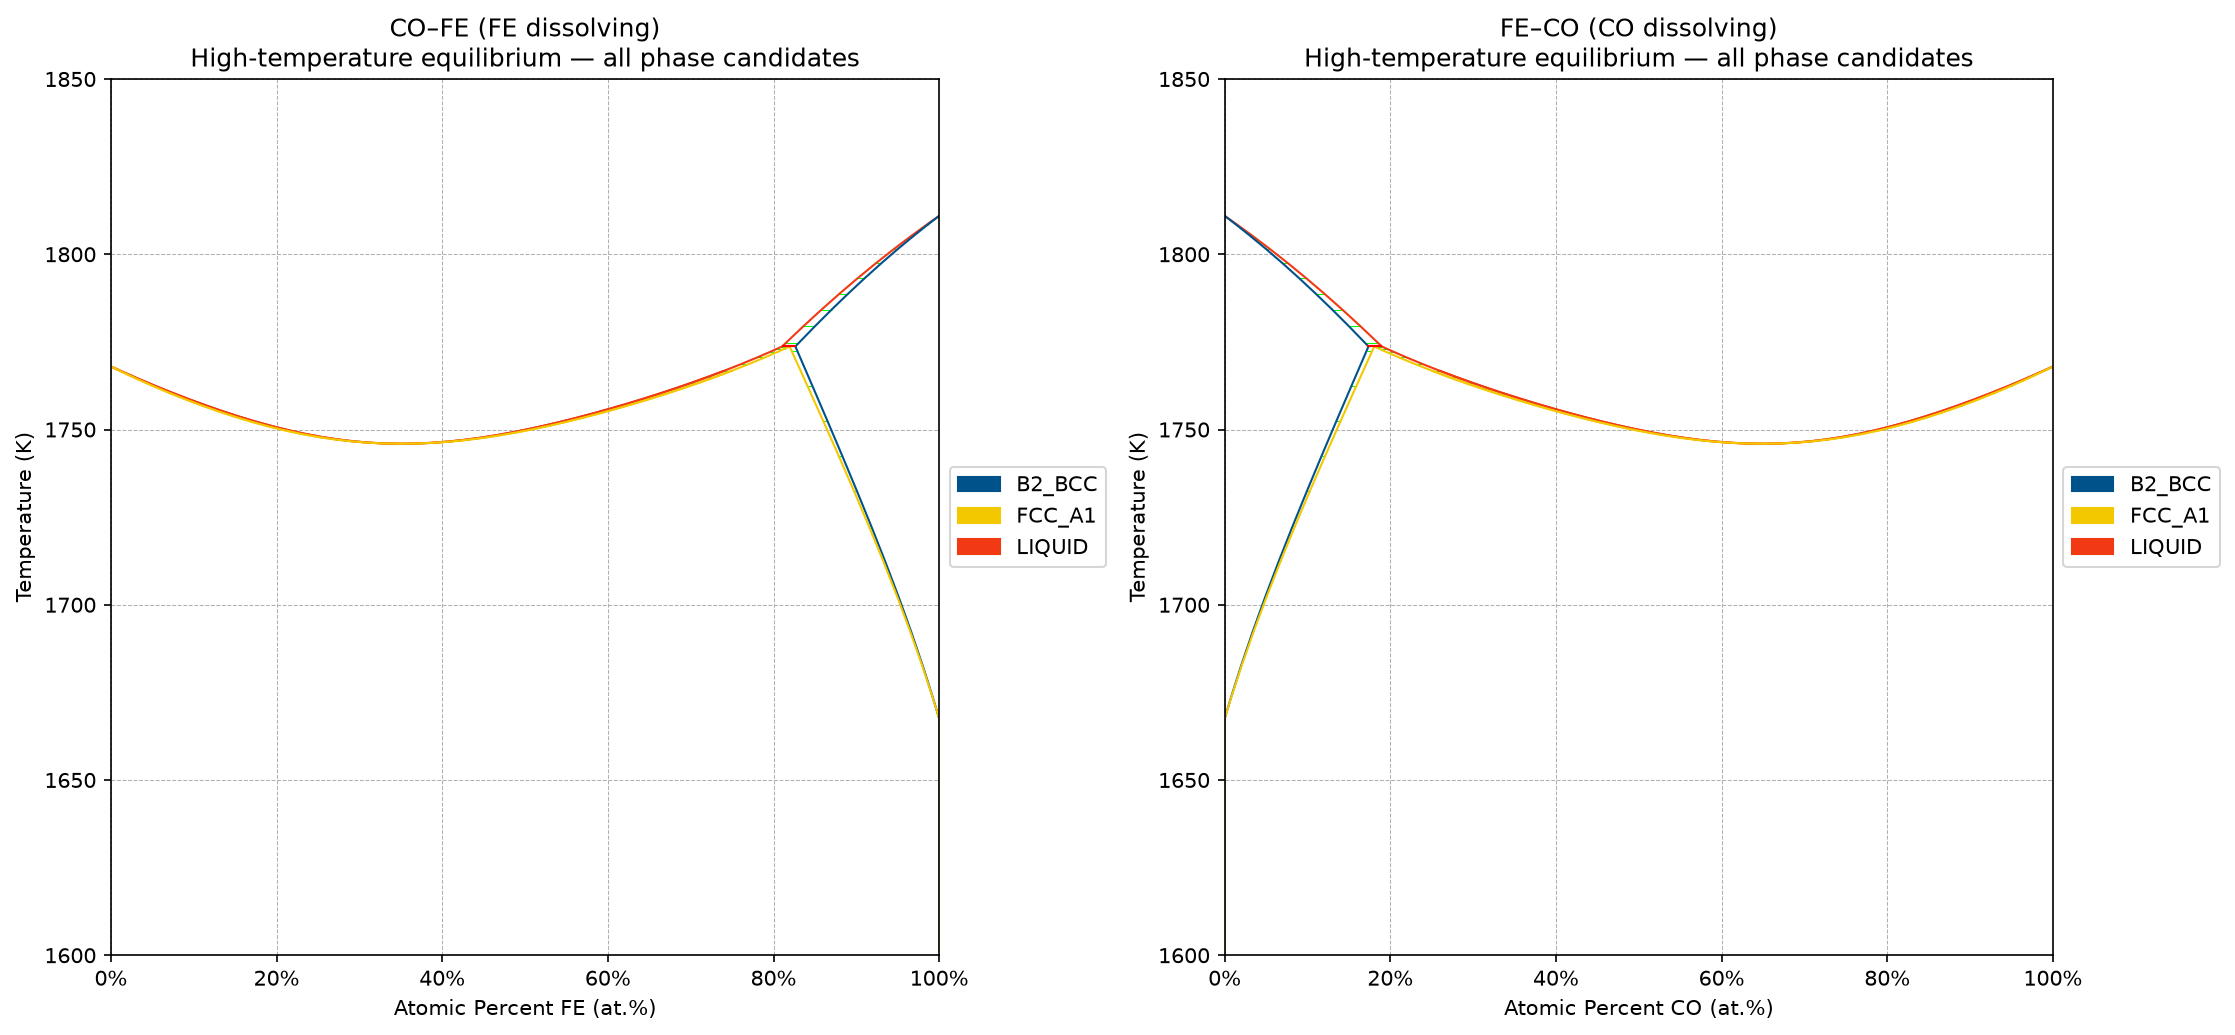

In [6]:
plot_diagram_pair(
    database,
    calculation_components,
    all_phases,
    full_atomic_fraction_range,
    equilibrium_temperature_range,
    "High-temperature equilibrium — all phase candidates",
)

## 3. Focused system: 10–25 at.% equilibrium liquidus/solidus

This section generates **two separate figures** so each dissolving-element direction can use an independent temperature scale:

- Co–Fe with Fe dissolving; and
- Fe–Co with Co dissolving.

The curves and markers are direct **all-phase equilibrium** solidus and liquidus results. The table records the stable solid phase or phases immediately below the liquid-containing field for each sampled composition.

Use `focused_y_axis_ranges` in the settings cell to zoom each temperature axis without changing the thermodynamic calculation. Set either value to `None` for the full calculation window.

### How the equilibrium liquidus/solidus boundary data points are calculated

The circular markers and tables are **not digitized or interpolated from the plotted curves**. For every selected composition, the notebook performs a new equilibrium calculation using the full focused phase set: `LIQUID`, `FCC_A1`, `BCC_A2`, `B2_BCC`, and `HCP_A3`.

For a dissolving-element concentration $c$ given in atomic percent, the equilibrium condition uses its atomic fraction:

$$
X_{\mathrm{dissolving}} = \frac{c}{100}, \qquad P = 101325\,\mathrm{Pa}, \qquad N = 1.
$$

At every trial temperature $T$, pycalphad minimizes total Gibbs energy using all listed phase candidates. The stable solid can change with composition, so the table explicitly identifies the phase or phases just below the first liquid-containing equilibrium.

The table reports two boundary temperatures for each composition:

- **Equilibrium solidus** $T_{\mathrm{s}}$: the first heating temperature where liquid is present,

$$
T_{\mathrm{s}} = \min\left\{T : n_{\mathrm{L}}(T, X) > \varepsilon\right\}.
$$

- **Equilibrium liquidus** $T_{\mathrm{L}}$: the first heating temperature where the material is effectively all liquid,

$$
T_{\mathrm{L}} = \min\left\{T : n_{\mathrm{L}}(T, X) \geq 1-\varepsilon\right\}.
$$

Here, $\varepsilon = 10^{-6}$ is `PHASE_AMOUNT_TOLERANCE`. Between $T_{\mathrm{s}}$ and $T_{\mathrm{L}}$, the stable solid or solids may change, so the yellow area represents the complete equilibrium solid-plus-liquid interval rather than one fixed two-phase field.

For efficiency, the code first scans the direction-specific `focused_boundary_temperature_ranges` in $5\,\mathrm{K}$ steps to bracket each transition. It then applies bisection until the bracket width is at most $0.1\,\mathrm{K}$ (`TEMPERATURE_TOLERANCE`). Therefore, the boundary values are direct all-phase equilibrium results with a transition-location uncertainty bounded by approximately $0.1\,\mathrm{K}$.

> **Database limitation:** pycalphad issues an order–disorder magnetic-energy warning when evaluating `B2_BCC`. The notebook preserves that phase because the TDB predicts it close to melting in part of the Fe–Co range; validate B2-containing results against independent thermodynamic assessments or experiments when high accuracy is required.

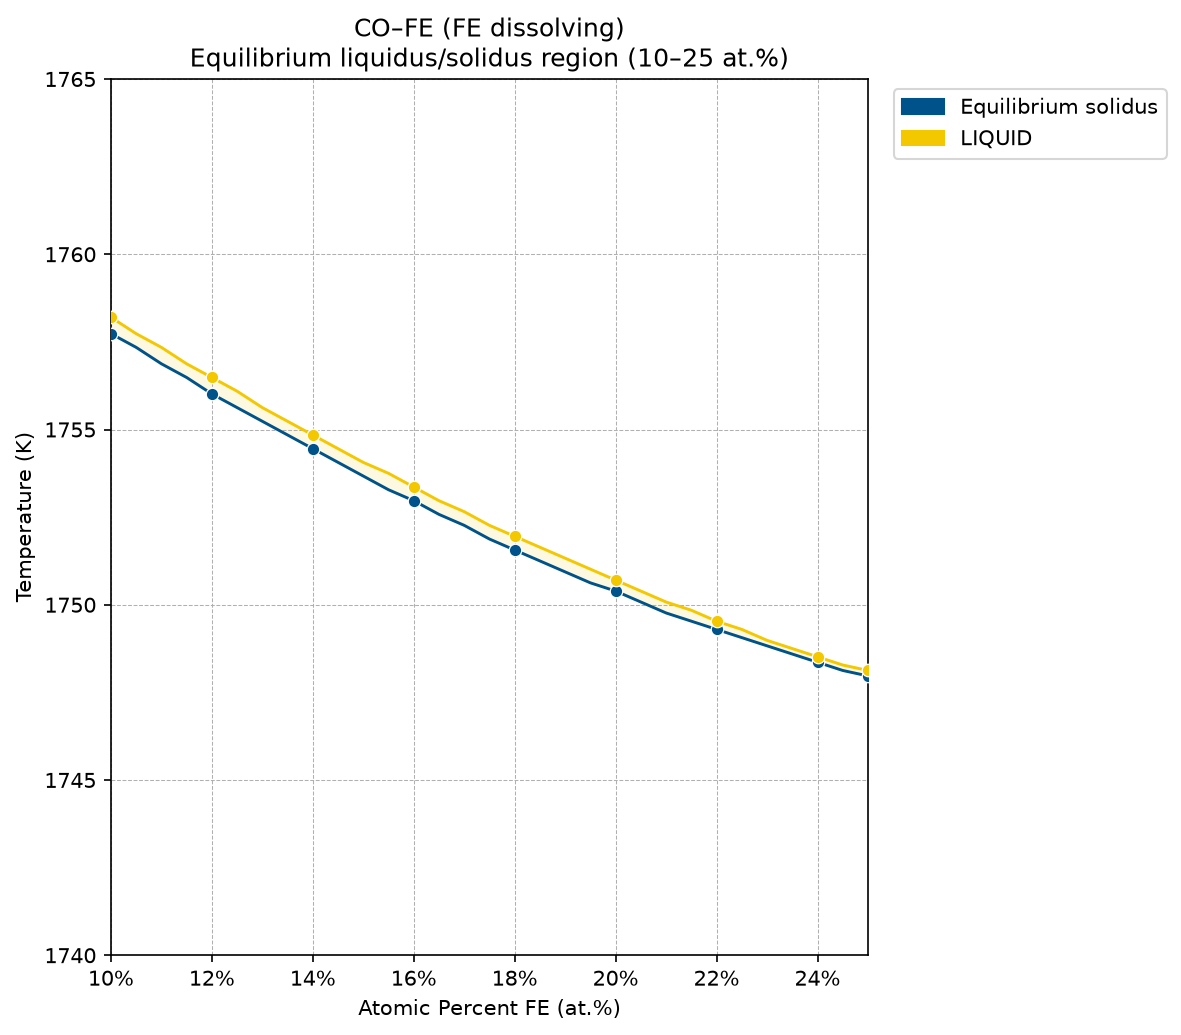

CO–FE (FE dissolving): selected equilibrium solidus and liquidus temperatures


,FE (at.%),Equilibrium solidus (K),Equilibrium liquidus (K),Stable solid phase(s) below solidus
0,10.0,1757.7,1758.2,FCC_A1
1,12.0,1756.0,1756.5,FCC_A1
2,14.0,1754.5,1754.8,FCC_A1
3,16.0,1753.0,1753.4,FCC_A1
4,18.0,1751.6,1752.0,FCC_A1
5,20.0,1750.4,1750.7,FCC_A1
6,22.0,1749.3,1749.5,FCC_A1
7,24.0,1748.4,1748.5,FCC_A1
8,25.0,1748.0,1748.1,FCC_A1


/home/volodymyr/Desktop/CALPHAD_analysis/calphad-venv/lib/python3.12/site-packages/pycalphad/model.py:1380: UserWarning: The order-disorder model for "B2_BCC" has a contribution from the physical property model `magnetic_energy`. Partitioned physical properties are not correctly substituted into the disordered part of the energy. THE GIBBS ENERGY CALCULATED FOR THIS PHASE MAY BE INCORRECT. Please see the discussion in https://github.com/pycalphad/pycalphad/pull/311 for more details.
  warnings.warn(


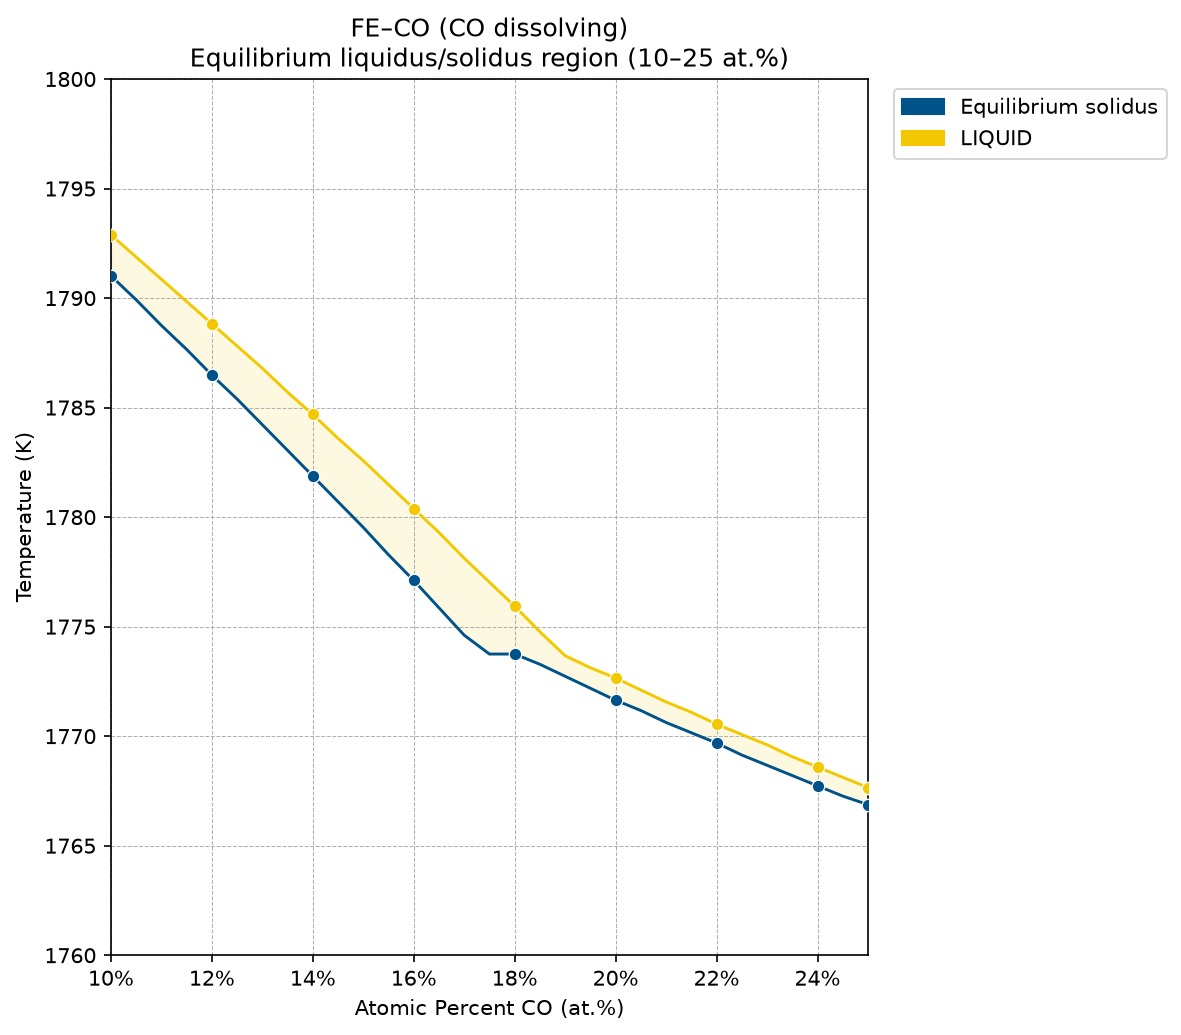

FE–CO (CO dissolving): selected equilibrium solidus and liquidus temperatures


,CO (at.%),Equilibrium solidus (K),Equilibrium liquidus (K),Stable solid phase(s) below solidus
0,10.0,1791.0,1792.9,B2_BCC
1,12.0,1786.5,1788.8,B2_BCC
2,14.0,1781.9,1784.7,B2_BCC
3,16.0,1777.1,1780.4,BCC_A2
4,18.0,1773.8,1775.9,BCC_A2 + FCC_A1
5,20.0,1771.6,1772.7,FCC_A1
6,22.0,1769.7,1770.5,FCC_A1
7,24.0,1767.7,1768.6,FCC_A1
8,25.0,1766.9,1767.7,FCC_A1


In [7]:
plot_focused_diagrams(
    database,
    calculation_components,
    focused_y_axis_ranges,
)